In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from main import make_keyhole, make_key, add_bottom, add_snaplock, KeyholeParams
from common.utils import show_svg, show_image
from dataclasses import replace

In [3]:
from jupyter_cadquery import show, open_viewer, set_defaults, show_object, reset_show, Camera
cv = open_viewer("Viewer", anchor="split-bottom", aspect_ratio=0)
set_defaults(edge_accuracy=0.0001, axes=True, reset_camera=Camera.KEEP)

Overwriting auto display for build123d BuildPart, BuildSketch, BuildLine, ShapeList


# Base geometry

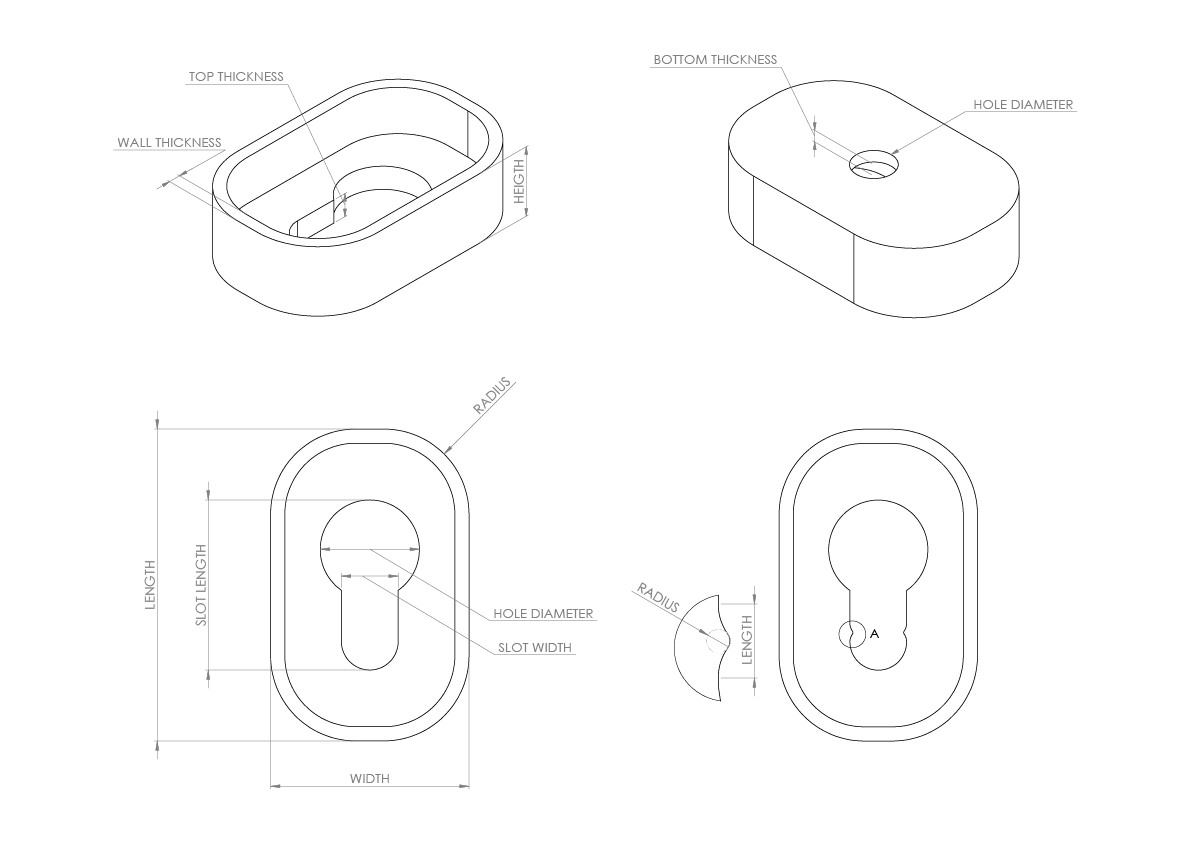

In [4]:
show_image("drawing.png")

In [5]:
params_slot = KeyholeParams(
    Length = 22.0,
    Width = 14.0,
    Height = 6.0,
    Radius = 6.0,
    WallThickness = 1.0,
    TopThickness = 2.0,
    HoleDiameter = 7.0,
    SlotWidth = 4.0,
    SlotLength = 12.0,
)

params_circle = replace(params_slot, Width=22, Radius=11)

part_slot = make_keyhole(params_slot)
part_circle = make_keyhole(params_circle)
show_svg(part_slot)
show_svg(part_circle)

### Bottom wall

To increase the glue area, you can add a bottom wall to the part. This wall can include an optional through-hole or countersunk hole, aligned with either the center of the part or the center of the top hole. Keep in mind that adding a bottom hole makes the part harder to 3D print.

In [6]:
with_bottom_a = add_bottom(
    part_slot, params_slot,
    BottomThickness=1.0,
    HoleType="simple",
    HoleDiameter=3.0
)

with_bottom_b = add_bottom(
    part_slot, params_slot,
    BottomThickness=1.0,
    HoleType="countersink",
    HoleLocation="center",
    HoleDiameter=3.0,
    CounterSinkDiameter=8.0,
)

show_svg(with_bottom_a, wireframe=True)
show_svg(with_bottom_b, wireframe=True)

### Snap-lock and key

In [7]:
with_snaplock = add_snaplock(part_slot, params_slot, Radius=.4)
show_svg(with_snaplock)

key = make_key(part_slot, params_slot)
show_svg(with_snaplock + key, wireframe=True)